# ML ASSIGNMENT - B2

Classify the email using the binary classification method. Email Spam detection has two states:

a) Normal State(0) - Not Spam<br>
b) Abnormal State(1) - Spam. 

Use K-Nearest Neighbors and Support Vector Machine for classification.<br>
Analyze their performance. 

<b>Dataset link: Email Spam Classification Dataset (Kaggle)</b><br>
https://www.kaggle.com/datasets/balaka18/email-spam-classification-dataset-csv 

### 1) Import libraries

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix,  
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

### 2) Load Dataset

In [63]:
df = pd.read_csv("emails.csv")

In [64]:
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [65]:
df.shape

(5172, 3002)

In [66]:
print("\nMissing Values:")
print(df.isna().sum().sum())


Missing Values:
0


In [67]:
print("\nSpam Distribution:")
print(df['Prediction'].value_counts())


Spam Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


<b>Visualize spam distribution</b>

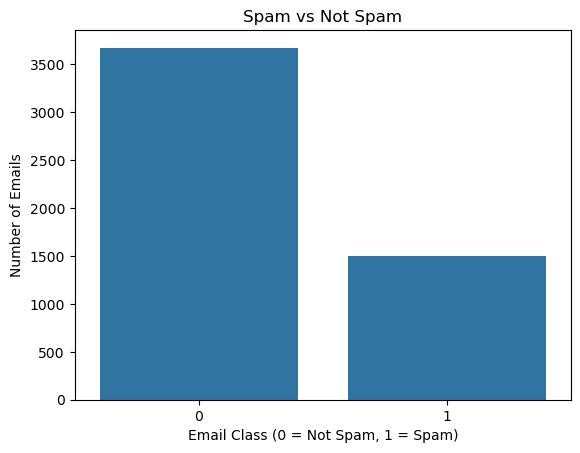

In [68]:
sns.countplot(x='Prediction', data=df)
plt.title("Spam vs Not Spam")
plt.xlabel("Email Class (0 = Not Spam, 1 = Spam)")
plt.ylabel("Number of Emails")
plt.show()

### 3) Preprocessing

Remove the email identifier column

In [69]:
# Remove Email No. column
df = df.drop(columns=['Email No.'])

### 4) Select features and split the dataset (80:20)

In [70]:
# Separate features and target
X = df.drop(columns=["Prediction"])
y = df["Prediction"]

In [71]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

### 5) Feature Scaling

In [72]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### 6) Implement K-Nearest Neighbors (KNN

We use K = 5

In [73]:
knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("Predictions:")
print(y_pred_knn)

Predictions:
[0 0 1 ... 0 1 0]


### 7) Implement Support Vector Machine (SVM)

We use a linear kernel for simple classification.

In [74]:
svm = SVC(kernel='linear')

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("Predictions:")
print(y_pred_svm)

Predictions:
[0 0 1 ... 0 1 0]


### 8) Confusion matrices
Visualize the performance of both models.

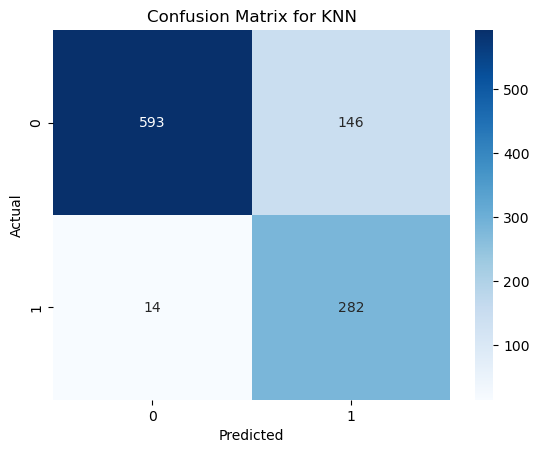

In [75]:
cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix for KNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

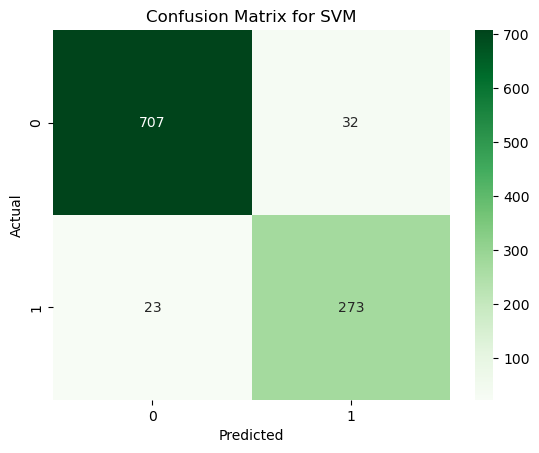

In [76]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion Matrix for SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 9) Compare model performance
Compare accuracy, precision, recall and F1-score.

In [77]:
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_svm)
    ],
    'Recall': [
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_svm)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_svm)
    ]
})

results.round(2)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.85,0.66,0.95,0.78
1,SVM,0.95,0.90,0.92,0.91
